# Protokoll Versuch 1: Kalibrierung und Einsatz eines Infrarot-Entfernungsmessers

**Praktikum Technische Grundlagen der KI**
Datum der Messung: 19.10.2026 · Beteiligte: Armin, Mamoon, Pascal

## 1 Ziel des Versuchs

In diesem Versuch wurde der Infrarot-Abstandssensor Sharp GP2Y0A21YK0F kalibriert und anschließend als Messgerät eingesetzt. Ziel war es, die Kennlinie $U(d)$ aufzunehmen, sie durch eine doppelt logarithmische lineare Regression als Umrechnungsvorschrift $d(U)$ zu modellieren und damit die Fläche eines DIN-A4-Blattes samt Messfehler zu bestimmen.

Der Sensor arbeitet nach dem Triangulationsprinzip: Eine IR-LED sendet einen schmalen Lichtstrahl aus, das vom Objekt reflektierte Licht fällt über eine zweite Linse auf einen positionsempfindlichen Detektor (PSD). Je nach Abstand trifft der Strahl an einer anderen Stelle auf, ein Signalprozessor setzt das in eine Ausgangsspannung um. Die Spannung sinkt mit wachsendem Abstand, laut Datenblatt liegt der Messbereich bei 10 bis 80 cm.

## 2 Versuchsaufbau und Durchführung

Der Sensor wurde über Output 3 des Netzgerätes mit fest 5 V Gleichspannung versorgt (Vcc rot an +, GND schwarz an −). Der Signalausgang Vo (gelb) war an Kanal A des PicoScope-Oszilloskops angeschlossen. Als Zielobjekt diente eine senkrecht zur Tischoberfläche stehende Platte, als Normal ein Meterstab. Gemessen wurde jeweils ab dem Gehäuseende des Sensors.

1. Für 20 Abstände zwischen 10 und 70 cm wurde die Platte eingestellt. Im steilen Nahbereich wurde dichter gemessen (10, 12, 14 … 22, 25, 28 … 40, 44, 48 … 60, 65, 70 cm).
2. Der Mittelwert der Spannung laut Messfunktion des Oszilloskops wurde handschriftlich ins Messprotokoll eingetragen.
3. Zu jedem Abstand wurde die aufgezeichnete Kurve als CSV-Datei exportiert (Zeitfenster −5 bis +5 ms, 96 158 Samples pro Datei).
4. Für Aufgabe 3 wurde die Platte je einmal auf 29,7 cm (lange A4-Seite) und 21,0 cm (kurze A4-Seite) gestellt und jeweils eine einzige Messung gespeichert.

Die Messdateien liegen im Ordner `daten/` (Kennlinie in `daten/kennlinie/`, Dateiname = Abstand), die handschriftlich abgelesenen Werte in `Messprotokoll_Versuch1.xlsx`.

In [1]:
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

DATEN = Path("daten")
SKIP = 1000          # erste Werte verwerfen (Einschwingvorgang)
D_MAX_FIT = 50.0     # nur Abstände <= 50 cm in die Regression (siehe Aufgabe 2)
A4_LAENGE, A4_BREITE = 29.7, 21.0   # Sollwerte DIN A4 in cm

def tabelle(kopf, zeilen):
    # Hilfsfunktion: Ergebnistabelle als Markdown anzeigen
    t = "| " + " | ".join(kopf) + " |\n|" + "---|" * len(kopf) + "\n"
    t += "\n".join("| " + " | ".join(z) + " |" for z in zeilen)
    display(Markdown(t))

def de(x, n=3):
    # Zahl mit Dezimalkomma formatieren
    return f"{x:.{n}f}".replace(".", ",")

## 3 Aufgabe 1: Kennlinie des Sensors

### 3.1 Einlesen der Messdaten

Das Oszilloskop speichert Dezimalzahlen im Format `XX,YY`, `np.genfromtxt()` erwartet aber `XX.YY`. Deshalb wird über das Argument `converters` für jede Spalte eine Funktion übergeben, die das Komma durch einen Punkt ersetzt. Die beiden Kopfzeilen der Datei (`Zeit;Kanal A` und die Einheiten) und die Leerzeile werden übersprungen.

Die Funktion `mittelwert_std()` verwirft anschließend die ersten 1000 Werte (Einschwingvorgang) und berechnet aus den restlichen Werten den Mittelwert und die empirische Standardabweichung $s$ (mit $n-1$).

In [2]:
def komma_zu_float(s):
    # Converter für genfromtxt: '0,6991' -> 0.6991
    s = s.decode() if isinstance(s, bytes) else s
    try:
        return float(s.strip().replace(",", "."))
    except ValueError:
        return np.nan          # z.B. '∞' bei Übersteuerung

def lade_oszi_csv(pfad):
    # Liest eine PicoScope-CSV ein und gibt das Signal von Kanal A zurück
    daten = np.genfromtxt(pfad, delimiter=";", skip_header=3,
                          converters={0: komma_zu_float, 1: komma_zu_float},
                          encoding="utf-8")
    daten = np.array(daten.tolist(), dtype=float)
    return daten[:, 1]

def mittelwert_std(pfad, skip=SKIP):
    u = lade_oszi_csv(pfad)[skip:]
    u = u[np.isfinite(u)]
    return u.mean(), u.std(ddof=1), len(u)

def abstand_aus_dateiname(pfad):
    return float(re.search(r"\d+(?:\.\d+)?", Path(pfad).stem).group())

### 3.2 Mittelwerte, Standardabweichung und Vergleich mit dem Messprotokoll

In [3]:
dateien = sorted((DATEN / "kennlinie").glob("*.csv"), key=abstand_aus_dateiname)
d, u, s, n = map(np.array, zip(*[(abstand_aus_dateiname(f), *mittelwert_std(f)) for f in dateien]))

# handschriftlich abgelesene Werte aus dem Messprotokoll
from openpyxl import load_workbook
ws = load_workbook("Messprotokoll_Versuch1.xlsx", data_only=True)["Messprotokoll"]
protokoll = {float(di): float(ui) for nr, di, ui in ws.iter_rows(min_col=1, max_col=3, values_only=True)
             if isinstance(nr, int) and isinstance(ui, (int, float))}
u_prot = np.array([protokoll[di] for di in d])

print(f"n = {n[0]} Werte pro Messung (nach Überspringen der ersten {SKIP})")
tabelle(["d [cm]", "Ū (CSV) [V]", "s [mV]", "U Protokoll [V]", "Differenz [mV]"],
        [[f"{di:g}", de(ui, 4), de(1000*si, 1), de(up, 3), de(1000*(ui-up), 1)]
         for di, ui, si, up in zip(d, u, s, u_prot)])

n = 95158 Werte pro Messung (nach Überspringen der ersten 1000)


| d [cm] | Ū (CSV) [V] | s [mV] | U Protokoll [V] | Differenz [mV] |
|---|---|---|---|---|
| 10 | 1,3399 | 24,8 | 1,340 | -0,1 |
| 12 | 1,2228 | 24,3 | 1,223 | -0,2 |
| 14 | 1,1524 | 25,5 | 1,153 | -0,6 |
| 16 | 1,0527 | 26,2 | 1,053 | -0,3 |
| 18 | 0,9938 | 25,4 | 0,993 | 0,8 |
| 20 | 0,9002 | 25,4 | 0,900 | 0,2 |
| 22 | 0,9010 | 26,0 | 0,900 | 1,0 |
| 25 | 0,7829 | 23,0 | 0,782 | 0,9 |
| 28 | 0,7868 | 21,9 | 0,786 | 0,8 |
| 31 | 0,7224 | 26,6 | 0,722 | 0,4 |
| 34 | 0,6861 | 25,3 | 0,686 | 0,1 |
| 37 | 0,6500 | 20,8 | 0,650 | 0,0 |
| 40 | 0,6276 | 26,4 | 0,627 | 0,6 |
| 44 | 0,5903 | 25,4 | 0,590 | 0,3 |
| 48 | 0,5672 | 22,4 | 0,567 | 0,2 |
| 52 | 0,4882 | 26,8 | 0,488 | 0,2 |
| 56 | 0,4885 | 28,2 | 0,488 | 0,5 |
| 60 | 0,4282 | 24,6 | 0,428 | 0,2 |
| 65 | 0,4144 | 24,2 | 0,414 | 0,4 |
| 70 | 0,3910 | 27,3 | 0,391 | 0,0 |

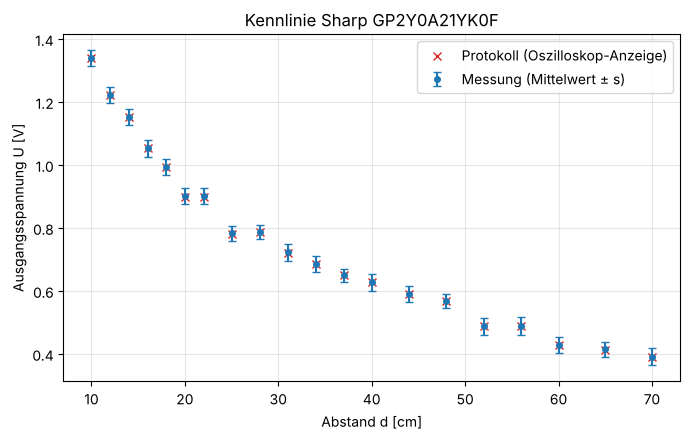

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(d, u, yerr=s, fmt="o", ms=4, capsize=3, label="Messung (Mittelwert ± s)")
ax.plot(d, u_prot, "x", color="C3", label="Protokoll (Oszilloskop-Anzeige)")
ax.set_xlabel("Abstand d [cm]"); ax.set_ylabel("Ausgangsspannung U [V]")
ax.set_title("Kennlinie Sharp GP2Y0A21YK0F"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

Die Ausgangsspannung fällt von 1,340 V bei 10 cm auf 0,391 V bei 70 cm. Die Kennlinie zeigt den erwarteten antiproportionalen Verlauf: steil im Nahbereich, flach bei großen Abständen. Die Streuung der Einzelwerte ist mit $s \approx 21$ bis $28$ mV bei allen Abständen etwa gleich groß.

Die Werte aus dem Handprotokoll und aus den CSV-Dateien stimmen auf höchstens 1 mV überein. Das ist zu erwarten, da beide aus derselben Aufzeichnung stammen.

**Hinweis:** Jeder Abstand wurde nur einmal eingestellt. Die Standardabweichung $s$ beschreibt deshalb nur das Rauschen innerhalb einer Aufnahme, nicht die Unsicherheit beim Einstellen des Abstands. Der Messfehler wird dadurch systematisch unterschätzt (siehe Diskussion).

## 4 Aufgabe 2: Modellierung der Kennlinie

Weil die Kennlinie nichtlinear ist, werden Spannung und Abstand logarithmiert: $x' = \ln U$ und $y' = \ln d$. Für eine Kennlinie der Form $y = x^a$ wird daraus eine Gerade $y' = a \cdot x' + b$. Ihre Parameter werden mit der linearen Regression aus der Vorlesung berechnet:

$$a = \frac{\sum_i (x'_i - \bar{x}')(y'_i - \bar{y}')}{\sum_i (x'_i - \bar{x}')^2}, \qquad b = \bar{y}' - a\,\bar{x}'$$

Die Rückrechnung ergibt die Umrechnungsvorschrift $d(U) = e^b \cdot U^a$.

**Wahl des Fitbereichs:** Im log-log-Plot liegen die Punkte bis 48 cm gut auf einer Geraden. Ab 52 cm knicken sie deutlich nach unten ab, der lineare Zusammenhang gilt dort nicht mehr. Wie in der Anleitung vorgesehen, werden diese fünf Punkte (52 bis 70 cm) aus der Regression herausgenommen.

In [5]:
def lineare_regression(x, y):
    # Ausgleichsgerade y = a*x + b nach Vorlesung
    xm, ym = x.mean(), y.mean()
    a = np.sum((x - xm) * (y - ym)) / np.sum((x - xm) ** 2)
    b = ym - a * xm
    return a, b

def kennlinie(u, a, b):
    return np.exp(b) * u ** a              # d = e^b * U^a

x_log, y_log = np.log(u), np.log(d)        # x' = ln U, y' = ln d
fit = d <= D_MAX_FIT
a, b = lineare_regression(x_log[fit], y_log[fit])

rest = y_log[fit] - (a * x_log[fit] + b)
r2 = 1 - np.sum(rest**2) / np.sum((y_log[fit] - y_log[fit].mean())**2)

# Vergleich: Fit über alle 20 Punkte
a_alle, b_alle = lineare_regression(x_log, y_log)
fehler_fit  = np.sqrt(np.mean((kennlinie(u[fit], a, b) - d[fit])**2))   # RMS-Abweichung
fehler_alle = np.sqrt(np.mean((kennlinie(u, a_alle, b_alle) - d)**2))

print(f"Regression über {fit.sum()} von {len(d)} Punkten (d <= {D_MAX_FIT:g} cm)")
print(f"a = {a:.4f},  b = {b:.4f},  R² = {r2:.4f}")
print(f"=> d(U) = e^b * U^a = {np.exp(b):.2f} cm * (U/V)^({a:.3f})")
print(f"RMS-Abweichung des Modells im Fitbereich: {fehler_fit:.2f} cm "
      f"(zum Vergleich, Fit über alle 20 Punkte: {fehler_alle:.2f} cm)")

Regression über 15 von 20 Punkten (d <= 50 cm)
a = -1.7778,  b = 2.8555,  R² = 0.9953
=> d(U) = e^b * U^a = 17.38 cm * (U/V)^(-1.778)
RMS-Abweichung des Modells im Fitbereich: 0.75 cm (zum Vergleich, Fit über alle 20 Punkte: 3.25 cm)


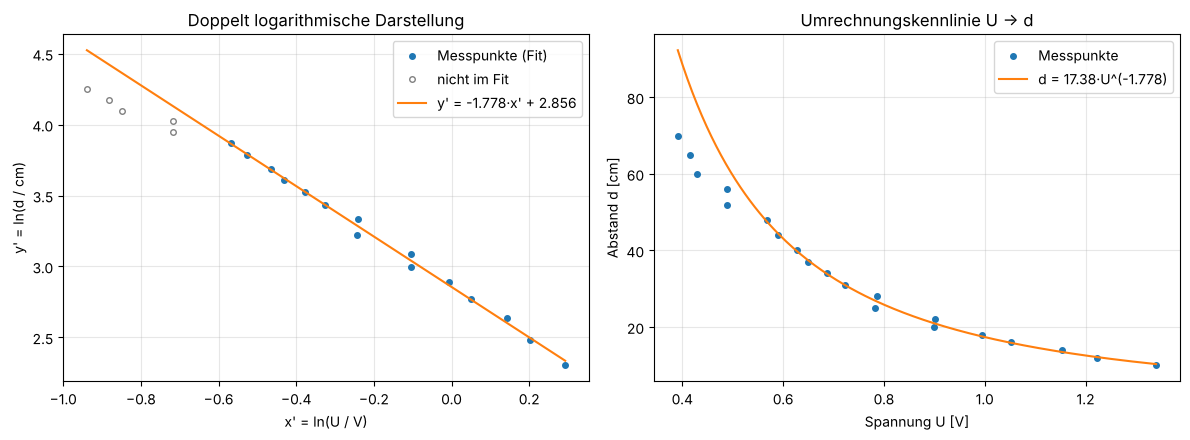

| d [cm] | d Modell [cm] | Abweichung [cm] |  |
|---|---|---|---|
| 10 | 10,33 | 0,33 |  |
| 12 | 12,16 | 0,16 |  |
| 14 | 13,51 | -0,49 |  |
| 16 | 15,87 | -0,13 |  |
| 18 | 17,58 | -0,42 |  |
| 20 | 20,95 | 0,95 |  |
| 22 | 20,92 | -1,08 |  |
| 25 | 26,86 | 1,86 |  |
| 28 | 26,62 | -1,38 |  |
| 31 | 30,99 | -0,01 |  |
| 34 | 33,96 | -0,04 |  |
| 37 | 37,39 | 0,39 |  |
| 40 | 39,79 | -0,21 |  |
| 44 | 44,38 | 0,38 |  |
| 48 | 47,64 | -0,36 |  |
| 52 | 62,19 | 10,19 | nicht im Fit |
| 56 | 62,13 | 6,13 | nicht im Fit |
| 60 | 78,51 | 18,51 | nicht im Fit |
| 65 | 83,23 | 18,23 | nicht im Fit |
| 70 | 92,28 | 22,28 | nicht im Fit |

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axs[0]
ax.plot(x_log[fit], y_log[fit], "o", ms=4, label="Messpunkte (Fit)")
ax.plot(x_log[~fit], y_log[~fit], "o", ms=4, mfc="none", color="gray", label="nicht im Fit")
xx = np.linspace(x_log.min(), x_log.max(), 100)
ax.plot(xx, a * xx + b, "-", color="C1", label=f"y' = {a:.3f}·x' + {b:.3f}")
ax.set_xlabel("x' = ln(U / V)"); ax.set_ylabel("y' = ln(d / cm)")
ax.set_title("Doppelt logarithmische Darstellung"); ax.grid(alpha=.3); ax.legend()

ax = axs[1]
ax.plot(u, d, "o", ms=4, label="Messpunkte")
uu = np.linspace(u.min(), u.max(), 200)
ax.plot(uu, kennlinie(uu, a, b), "-", color="C1", label=f"d = {np.exp(b):.2f}·U^({a:.3f})")
ax.set_xlabel("Spannung U [V]"); ax.set_ylabel("Abstand d [cm]")
ax.set_title("Umrechnungskennlinie U → d"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

tabelle(["d [cm]", "d Modell [cm]", "Abweichung [cm]", ""],
        [[f"{di:g}", de(dm, 2), de(dm - di, 2), "" if f else "nicht im Fit"]
         for di, dm, f in zip(d, kennlinie(u, a, b), fit)])

**Ergebnis:** Die Regression über die 15 Messpunkte von 10 bis 48 cm ergibt

$$\ln d = -1{,}778 \cdot \ln U + 2{,}856 \quad\Rightarrow\quad d(U) = 17{,}38\,\mathrm{cm} \cdot \left(\frac{U}{\mathrm{V}}\right)^{-1{,}778}, \qquad R^2 = 0{,}995$$

Mit allen 20 Punkten läge die mittlere quadratische Abweichung (RMS) des Modells bei 3,3 cm, ohne die fünf Punkte ab 52 cm bei 0,75 cm. Im Fitbereich weicht das Modell um höchstens 1,9 cm von den eingestellten Abständen ab. Die größten Abweichungen treten bei 20/22 cm und 25/28 cm auf, wo zwei Abstände fast dieselbe Spannung geliefert haben (siehe Diskussion). Außerhalb des Fitbereichs überschätzt das Modell den Abstand um 10 bis 22 cm und ist dort nicht verwendbar.

## 5 Aufgabe 3: Flächenmessung mit Fehlerrechnung

### 5.1 Vorgehen

**Messfehler der Spannung (3a).** Für die Länge wurde die Platte auf 29,7 cm gestellt und eine einzige Messung gespeichert, für die Breite auf 21,0 cm. Der Messfehler des Mittelwerts wird nach der Methode aus der Vorlesung geschätzt:

$$s_{\bar{x}} = \frac{s}{\sqrt{n}}, \qquad \Delta U = t \cdot s_{\bar{x}}$$

Der Korrekturfaktor $t$ berücksichtigt die endliche Anzahl der Messungen. Bei $n > 100$ ist laut Vorlesungstabelle $t = 1{,}00$ für 68 % und $t = 1{,}98$ für 95 % (der Grenzwert für sehr große $n$ wäre 1,96).

**Fehlerfortpflanzung durch die Kennlinie (3a).** Der Abstand wird über $d = e^b \cdot U^a$ aus der Spannung berechnet, der Spannungsfehler pflanzt sich über die Ableitung fort:

$$\Delta d = \left|\frac{\mathrm{d}d}{\mathrm{d}U}\right| \cdot \Delta U = \left| a \cdot e^{b} \cdot U^{a-1} \right| \cdot \Delta U$$

**Fläche (3b).** Für $A = l \cdot w$ gilt nach dem Gaußschen Fehlerfortpflanzungsgesetz:

$$\Delta A = \sqrt{\left(\frac{\partial A}{\partial l}\Delta l\right)^2 + \left(\frac{\partial A}{\partial w}\Delta w\right)^2} = \sqrt{(w\,\Delta l)^2 + (l\,\Delta w)^2}$$

In [7]:
# Korrekturfaktoren t aus der Vorlesungstabelle für P = 68,26 % und P = 95 %
T_TABELLE = {2: (1.84, 12.71), 3: (1.32, 4.30), 4: (1.20, 3.18), 5: (1.15, 2.78),
             6: (1.11, 2.57), 7: (1.09, 2.45), 8: (1.08, 2.37), 9: (1.07, 2.31),
             10: (1.06, 2.26), 15: (1.04, 2.15), 20: (1.03, 2.09), 30: (1.02, 2.05),
             50: (1.01, 2.01), 80: (1.00, 1.99), 100: (1.00, 1.98), np.inf: (1.00, 1.96)}

def t_faktor(n):
    # konservativ: nächstkleinerer tabellierter Wert
    return T_TABELLE[max(k for k in T_TABELLE if k <= n)]

def einzelmessung(pfad):
    um, s_, n_ = mittelwert_std(pfad)
    sx = s_ / np.sqrt(n_)
    t68, t95 = t_faktor(n_)
    du = {68: t68 * sx, 95: t95 * sx}
    d_ = kennlinie(um, a, b)
    abl = abs(a * np.exp(b) * um ** (a - 1))       # |dd/dU|
    dd = {p: abl * du[p] for p in du}
    return dict(U=um, s=s_, n=n_, sx=sx, t=(t68, t95), dU=du, d=d_, abl=abl, dd=dd)

L = einzelmessung(DATEN / "a4_laenge.csv")
B = einzelmessung(DATEN / "a4_breite.csv")
print(f"n = {L['n']},  t68 = {L['t'][0]},  t95 = {L['t'][1]}")

n = 95158,  t68 = 1.0,  t95 = 1.98


### 5.2 Ergebnis der Spannungsmessung (3a)

In [8]:
mV = lambda x: de(1000 * x, 2)
tabelle(["Größe", "Länge (Soll 29,7 cm)", "Breite (Soll 21,0 cm)"], [
    ["Mittelwert Ū", de(L["U"], 5) + " V", de(B["U"], 5) + " V"],
    ["Standardabweichung s", mV(L["s"]) + " mV", mV(B["s"]) + " mV"],
    ["s/√n", de(1000*L["sx"], 3) + " mV", de(1000*B["sx"], 3) + " mV"],
    *[[f"U bei P = {p} %", f"({mV(L['U'])} ± {mV(L['dU'][p])}) mV", f"({mV(B['U'])} ± {mV(B['dU'][p])}) mV"] for p in (68, 95)],
    *[[f"Vertrauensbereich {p} %", f"[{mV(L['U']-L['dU'][p])}; {mV(L['U']+L['dU'][p])}] mV",
       f"[{mV(B['U']-B['dU'][p])}; {mV(B['U']+B['dU'][p])}] mV"] for p in (68, 95)],
])

| Größe | Länge (Soll 29,7 cm) | Breite (Soll 21,0 cm) |
|---|---|---|
| Mittelwert Ū | 0,70520 V | 0,90283 V |
| Standardabweichung s | 23,50 mV | 26,57 mV |
| s/√n | 0,076 mV | 0,086 mV |
| U bei P = 68 % | (705,20 ± 0,08) mV | (902,83 ± 0,09) mV |
| U bei P = 95 % | (705,20 ± 0,15) mV | (902,83 ± 0,17) mV |
| Vertrauensbereich 68 % | [705,13; 705,28] mV | [902,75; 902,92] mV |
| Vertrauensbereich 95 % | [705,05; 705,35] mV | [902,66; 903,00] mV |

### 5.3 Ergebnis der Abstandsmessung (3a)

In [9]:
tabelle(["Größe", "Länge", "Breite"], [
    ["Empfindlichkeit \\|dd/dU\\|", de(L["abl"], 1) + " cm/V", de(B["abl"], 1) + " cm/V"],
    *[[f"d bei P = {p} %", f"({de(L['d'])} ± {de(L['dd'][p])}) cm", f"({de(B['d'])} ± {de(B['dd'][p])}) cm"] for p in (68, 95)],
    ["Sollwert", "29,7 cm", "21,0 cm"],
    ["Abweichung vom Sollwert",
     f"{L['d']-A4_LAENGE:+.2f} cm ({100*(L['d']-A4_LAENGE)/A4_LAENGE:+.1f} %)".replace(".", ","),
     f"{B['d']-A4_BREITE:+.2f} cm ({100*(B['d']-A4_BREITE)/A4_BREITE:+.1f} %)".replace(".", ",")],
])

| Größe | Länge | Breite |
|---|---|---|
| Empfindlichkeit \|dd/dU\| | 81,5 cm/V | 41,1 cm/V |
| d bei P = 68 % | (32,345 ± 0,006) cm | (20,848 ± 0,004) cm |
| d bei P = 95 % | (32,345 ± 0,012) cm | (20,848 ± 0,007) cm |
| Sollwert | 29,7 cm | 21,0 cm |
| Abweichung vom Sollwert | +2,64 cm (+8,9 %) | -0,15 cm (-0,7 %) |

### 5.4 Flächenmessung (3b)

In [10]:
l, w = L["d"], B["d"]
A = l * w
A_soll = A4_LAENGE * A4_BREITE
for p in (68, 95):
    dA = np.sqrt((w * L["dd"][p])**2 + (l * B["dd"][p])**2)
    print(f"P = {p} %:  A = ({A:.1f} ± {dA:.1f}) cm²")
print(f"Sollwert: {A4_LAENGE} cm · {A4_BREITE} cm = {A_soll:.1f} cm²")
print(f"Abweichung: {A - A_soll:+.1f} cm² ({100*(A - A_soll)/A_soll:+.1f} %)")

P = 68 %:  A = (674.3 ± 0.2) cm²
P = 95 %:  A = (674.3 ± 0.3) cm²
Sollwert: 29.7 cm · 21.0 cm = 623.7 cm²
Abweichung: +50.6 cm² (+8.1 %)


**Ergebnis:** Die Länge beträgt $(32{,}345 \pm 0{,}012)$ cm, die Breite $(20{,}848 \pm 0{,}007)$ cm, die Fläche des A4-Blattes damit

$$A = (674{,}3 \pm 0{,}3)\,\mathrm{cm}^2 \quad (P = 95\,\%)$$

Der Sollwert beträgt 623,7 cm². Die Abweichung von +50,6 cm² ist etwa 150-mal größer als der berechnete Fehler, der Sollwert liegt also weit außerhalb des Vertrauensbereichs.

## 6 Diskussion

Der berechnete Messfehler von wenigen hundertstel Millimetern ist unrealistisch klein, die tatsächliche Abweichung liegt im Zentimeterbereich.

**Systematische Unterschätzung des Messfehlers.** Die Fehlerrechnung erfasst nur das Rauschen der Spannung innerhalb einer Aufnahme. Weil $n = 95\,158$ sehr groß ist, wird $s/\sqrt{n}$ winzig. Wie im Arbeitsblatt angemerkt, wurde jeder Abstand aber nur einmal eingestellt. Fehler beim Einstellen und Ablesen am Meterstab, bei der Ausrichtung der Platte und beim Bezugspunkt (Gehäuseende) gehen deshalb gar nicht in die Rechnung ein. Außerdem sind die Samples nicht unabhängig voneinander: Das Zeitfenster beträgt nur 10 ms, während der Sensor laut Datenblatt etwa alle 38 ms einen neuen Messwert ausgibt. Eine Aufnahme enthält also höchstens einen echten Messzyklus, und die Annahme von $n$ unabhängigen Messungen ist nicht erfüllt.

**Abweichung der Längenmessung.** Die Breite wurde mit −0,7 % gut getroffen, die Länge liegt dagegen 2,6 cm (+8,9 %) zu hoch. Die Ursache liegt in der Messung, nicht im Modell: Die gemessene Spannung von 0,705 V liegt in der eigenen Kennlinie zwischen den Punkten für 31 cm (0,722 V) und 34 cm (0,686 V), also bei etwa 32 cm. Wahrscheinlich stand die Platte bei dieser Messung nicht genau bei 29,7 cm oder wurde von einem anderen Bezugspunkt aus gemessen. Der Fehler der Länge überträgt sich direkt auf die Fläche (+8,1 %).

**Auffällige Messpunkte.** Drei Abstandspaare liefern fast dieselbe Spannung: 20 und 22 cm (0,900 V / 0,901 V), 25 und 28 cm (0,783 V / 0,787 V) sowie 52 und 56 cm (je 0,488 V). Ein Unterschied von 2 bis 4 cm müsste sich in der Kennlinie deutlich zeigen. Vermutlich wurde die Platte zwischen diesen Messungen nicht oder nicht korrekt verschoben. Genau diese Punkte verursachen die größten Residuen der Regression.

**Rauschen und Auflösung.** Das Signal schwankt stark und ist grob quantisiert, wie der folgende Ausschnitt der Messung bei 20 cm zeigt.

20 cm: Spannung zwischen 0.42 V und 1.35 V, kleinste Stufe 46.6 mV


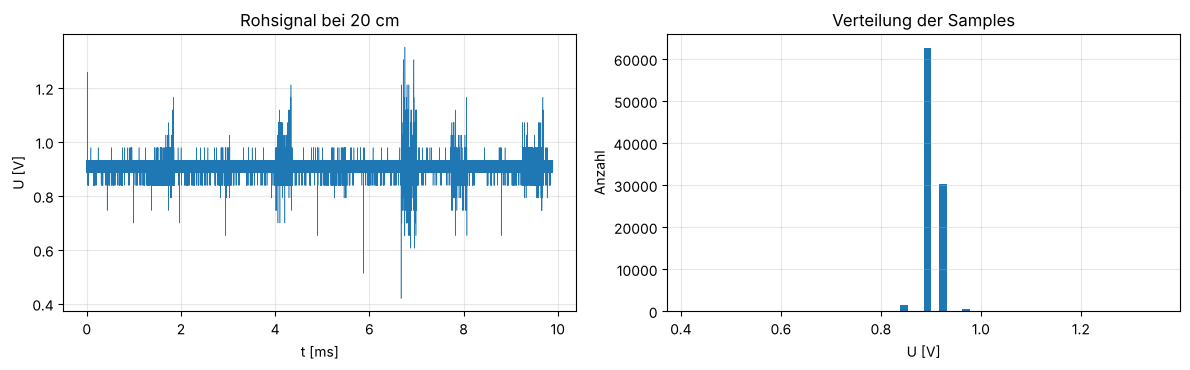

In [11]:
roh = lade_oszi_csv(DATEN / "kennlinie" / "20cm.csv")[SKIP:]
stufe = np.diff(np.unique(roh)).min()
print(f"20 cm: Spannung zwischen {roh.min():.2f} V und {roh.max():.2f} V, kleinste Stufe {1000*stufe:.1f} mV")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
t = np.arange(len(roh)) * 10 / 96158       # Zeitachse in ms (10 ms Fenster)
axs[0].plot(t, roh, lw=.4)
axs[0].set_xlabel("t [ms]"); axs[0].set_ylabel("U [V]"); axs[0].set_title("Rohsignal bei 20 cm")
axs[1].hist(roh, bins=60)
axs[1].set_xlabel("U [V]"); axs[1].set_ylabel("Anzahl"); axs[1].set_title("Verteilung der Samples")
for ax in axs: ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

Ursachen für das Rauschen sind die Strompulse der IR-LED (das Datenblatt empfiehlt einen Stützkondensator an der Versorgung) und der große eingestellte Messbereich am Oszilloskop, der zur groben Quantisierung führt. Ein kleinerer Messbereich, z. B. ±2 V, hätte eine feinere Auflösung ergeben.

**Vergleich mit dem Datenblatt.** Die gemessenen Spannungen sind niedriger als die typische Kennlinie im Datenblatt (dort etwa 2,3 V bei 10 cm, hier 1,34 V). Mögliche Gründe sind das Reflexionsvermögen der Platte (das Datenblatt verwendet weißes Papier mit 90 % Reflexion), ein anderer Bezugspunkt für den Abstand und Exemplarstreuung des Sensors.

**Gültigkeitsbereich des Modells.** Das Potenzgesetz beschreibt die Kennlinie nur bis etwa 50 cm. Darüber wird die Kennlinie flach, und die Empfindlichkeit $|\mathrm{d}d/\mathrm{d}U|$ steigt stark an: Bei der Länge (32 cm) bewirkt 1 mV Spannungsfehler 0,08 cm Abstandsfehler, bei der Breite (21 cm) nur 0,04 cm. Zusätzlich wurde die Unsicherheit der Regressionsparameter $a$ und $b$ nicht in die Fehlerfortpflanzung einbezogen.

**Verbesserungen.** Jeden Abstand mehrmals neu einstellen (z. B. 5-mal) und Mittelwert und Standardabweichung über diese Wiederholungen bilden, mit dem passenden $t$-Faktor für kleines $n$. Außerdem längere Aufnahmen über mehrere Messzyklen des Sensors, einen kleineren Messbereich am Oszilloskop und einen Kondensator an der Versorgung verwenden.

## 7 Fazit

Die Kennlinie des Sharp-Sensors lässt sich zwischen 10 und 50 cm gut durch das Potenzgesetz $d = 17{,}38\,\mathrm{cm} \cdot U^{-1{,}778}$ beschreiben ($R^2 = 0{,}995$, RMS-Abweichung 0,75 cm). Die Fläche des A4-Blattes wurde zu $(674{,}3 \pm 0{,}3)\,\mathrm{cm}^2$ bestimmt, 8,1 % über dem Sollwert von 623,7 cm². Die Abweichung geht fast vollständig auf die Längenmessung zurück. Der Versuch zeigt vor allem, dass eine Fehlerrechnung aus einer einzigen Aufnahme mit vielen Samples den Messfehler massiv unterschätzt. Für eine realistische Fehlerabschätzung müsste jeder Abstand mehrfach neu eingestellt werden.